# Experiment 6 — Model Evaluation

CSE4007L · Fake News Detection · Krishna Kaushik · 230160223030

**Run `experiment3.ipynb` and `experiment5.ipynb` first** — this notebook needs
`test.csv`, `tfidf.joblib`, `tfidf_noleak.joblib`, `model_best.joblib`,
`model_logreg.joblib` and `model_best_noleak.joblib`.

    pip3 install pandas scikit-learn joblib matplotlib

Runtime about 10 seconds.


In [1]:
import joblib, pandas as pd, matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)

REAL_C, FAKE_C = "#2A6FB5", "#D97706"        # colour-blind-safe pair

def style(ax, title, xlabel, ylabel=""):
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel(xlabel, fontsize=9); ax.set_ylabel(ylabel, fontsize=9)

## 1. Load the test set and the saved models

In [2]:
te = pd.read_csv("test.csv").dropna()                 # held out since Experiment 3
tfidf, tfidf_nl = joblib.load("tfidf.joblib"), joblib.load("tfidf_noleak.joblib")
models = {
    "Linear SVM (selected)": (joblib.load("model_best.joblib"),        tfidf),
    "Logistic Regression":   (joblib.load("model_logreg.joblib"),      tfidf),
    "Linear SVM, no leak":   (joblib.load("model_best_noleak.joblib"), tfidf_nl),
}
yte = te.label
print("Test records:", len(te), " Real:", (yte == 0).sum(), " Fake:", (yte == 1).sum())

Test records: 5798  Real: 3180  Fake: 2618


## 2. Metrics on the held-out test set

In [3]:
rows, pred, score = [], {}, {}
for name, (m, vec) in models.items():
    X = vec.transform(te.text)
    pred[name], score[name] = m.predict(X), m.decision_function(X)
    p = pred[name]
    rows.append([name, accuracy_score(yte, p), precision_score(yte, p),
                 recall_score(yte, p), f1_score(yte, p), roc_auc_score(yte, score[name])])

res = pd.DataFrame(rows, columns=["model", "accuracy", "precision", "recall", "f1", "roc_auc"]).round(4)
print(res.to_string(index=False))

                model  accuracy  precision  recall     f1  roc_auc
Linear SVM (selected)    0.9840     0.9880  0.9763 0.9821   0.9981
  Logistic Regression    0.9838     0.9880  0.9759 0.9819   0.9980
  Linear SVM, no leak    0.9809     0.9827  0.9748 0.9787   0.9977


## 3. Confusion matrix

             pred real  pred fake
actual real       3149         31
actual fake         62       2556

False positives (real flagged as fake): 31
False negatives (fake missed)         : 62


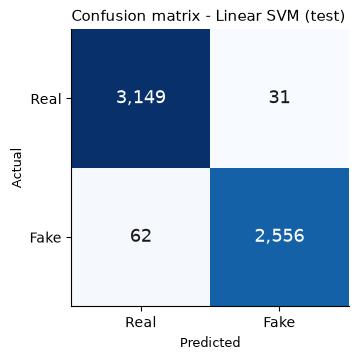

In [4]:
best = "Linear SVM (selected)"
cm = confusion_matrix(yte, pred[best])
print(pd.DataFrame(cm, index=["actual real", "actual fake"],
                   columns=["pred real", "pred fake"]))
print("\nFalse positives (real flagged as fake):", cm[0, 1])
print("False negatives (fake missed)         :", cm[1, 0])

fig, ax = plt.subplots(figsize=(4.2, 3.6))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=13,
                color="white" if cm[i, j] > cm.max() / 2 else "#1a1a1a")
ax.set_xticks([0, 1], ["Real", "Fake"]); ax.set_yticks([0, 1], ["Real", "Fake"])
style(ax, "Confusion matrix - Linear SVM (test)", "Predicted", "Actual")
plt.savefig("fig6_1_confusion.png", dpi=150, bbox_inches="tight"); plt.show(); plt.close()

## 4. ROC curve and AUC

Linear SVM (selected)    AUC 0.9981
Logistic Regression      AUC 0.9980
Linear SVM, no leak      AUC 0.9977


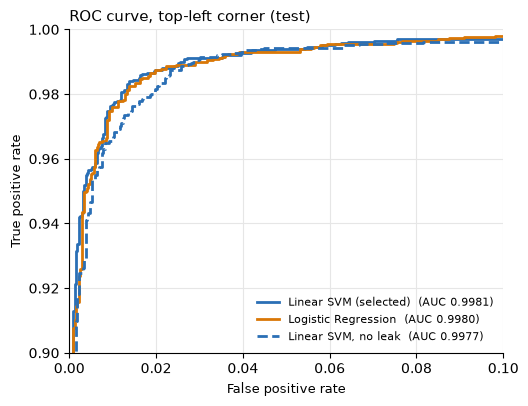


Threshold sensitivity (default = 0.0):
  threshold +0.5  recall 0.9248  precision 0.9979  flagged 2426
  threshold +0.0  recall 0.9763  precision 0.9880  flagged 2587
  threshold -0.5  recall 0.9935  precision 0.9469  flagged 2747


In [5]:
fig, ax = plt.subplots(figsize=(5.6, 4.2))
for name, colour, ls in [(best, REAL_C, "-"), ("Logistic Regression", FAKE_C, "-"),
                         ("Linear SVM, no leak", REAL_C, "--")]:
    fpr, tpr, _ = roc_curve(yte, score[name])
    ax.plot(fpr, tpr, color=colour, ls=ls, lw=2,
            label=f"{name}  (AUC {roc_auc_score(yte, score[name]):.4f})")
    print(f"{name:24s} AUC {roc_auc_score(yte, score[name]):.4f}")
ax.set_xlim(0, 0.10); ax.set_ylim(0.90, 1.0)
ax.grid(color="#E6E6E6", lw=0.8); ax.legend(frameon=False, fontsize=8, loc="lower right")
style(ax, "ROC curve, top-left corner (test)", "False positive rate", "True positive rate")
plt.savefig("fig6_2_roc.png", dpi=150, bbox_inches="tight"); plt.show(); plt.close()

print("\nThreshold sensitivity (default = 0.0):")
for t in [0.5, 0.0, -0.5]:
    p = (score[best] > t).astype(int)
    print(f"  threshold {t:+.1f}  recall {recall_score(yte, p):.4f}  "
          f"precision {precision_score(yte, p):.4f}  flagged {p.sum()}")

## 5. Error analysis

In [6]:
te["pred"] = pred[best]
te["words"] = te.text.str.split().str.len()
wrong = te[te.pred != te.label]
print("Misclassified:", len(wrong), "of", len(te), f"({len(wrong) / len(te) * 100:.2f} %)")
print("Mean words - correct:", round(te[te.pred == te.label].words.mean(), 1),
      "| wrong:", round(wrong.words.mean(), 1))

real = te[te.label == 0]
has_said = real.text.str.contains(r"\bsaid\b")
print("\nReal articles WITH 'said'    - error rate:",
      f"{(real[has_said].pred == 1).mean() * 100:.2f} %  (n={has_said.sum()})")
print("Real articles WITHOUT 'said' - error rate:",
      f"{(real[~has_said].pred == 1).mean() * 100:.2f} %  (n={(~has_said).sum()})")

print("\nSample missed fakes (predicted real):")
for t in wrong[wrong.label == 1].text.head(4):
    print("  -", t[:95])
print("\nSample real articles flagged as fake:")
for t in wrong[wrong.label == 0].text.head(4):
    print("  -", t[:95])

Misclassified: 93 of 5798 (1.60 %)
Mean words - correct: 421.1 | wrong: 437.8

Real articles WITH 'said'    - error rate: 0.77 %  (n=2983)
Real articles WITHOUT 'said' - error rate: 4.06 %  (n=197)

Sample missed fakes (predicted real):
  - breaking russia smells obama s foreign policy weakness and makes a move leading from behind has
  - breaking angry black lives matter activist admits to starting massive la apartment complex fire
  - n dakota legislator proposes bill to protect motorists if they hit pipeline protesters intentio
  - nsa architect nsa snooping expires but feds will continue surveillance of americans phone recor

Sample real articles flagged as fake:
  - american fanfare for canada s pm raises eyebrows back home toronto the attention paid by americ
  - text of michael flynn s letter resigning as national security adviser washington national secur
  - women in male dominated career fields watch a unique u s presidential campaign los angeles dr l
  - factbox trump plan t

## 6. Final model selection

In [7]:
print(res.set_index("model")[["recall", "f1", "roc_auc"]].to_string())
print("\nSelected: Linear SVM (C = 5)\n")
print(classification_report(yte, pred[best], target_names=["real", "fake"], digits=4))

final = make_pipeline(tfidf, models[best][0])       # vectoriser + model in one object
joblib.dump(final, "final_pipeline.joblib")
print("Saved: final_pipeline.joblib")

                       recall      f1  roc_auc
model                                         
Linear SVM (selected)  0.9763  0.9821   0.9981
Logistic Regression    0.9759  0.9819   0.9980
Linear SVM, no leak    0.9748  0.9787   0.9977

Selected: Linear SVM (C = 5)

              precision    recall  f1-score   support

        real     0.9807    0.9903    0.9854      3180
        fake     0.9880    0.9763    0.9821      2618

    accuracy                         0.9840      5798
   macro avg     0.9844    0.9833    0.9838      5798
weighted avg     0.9840    0.9840    0.9840      5798

Saved: final_pipeline.joblib
